[Use PyTorch for all questions]

In [1]:
import copy
import math
import random
import time
from collections import Counter
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

torch.manual_seed(0)
random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

## Predicting the next word with an RNN

Our goal: read a text word by word, and at every position predict the **next word**.

```
input :  the   cat   sat   on    the
target:  cat   sat   on    the   mat
```

In the lecture, we built a recurrent cell from scratch (and saw why gradients vanish through time), and we saw why words are not fed to the network as one-hot vectors: each word is **embedded** (`nn.Embedding`), and the network predicts a small vector that a decoder turns into word scores. Here we use PyTorch's `nn.GRU` and `nn.Embedding`.

We will:
1. train the same RNN three times:
    - on top of the CBOW embedding of Session 8 (frozen),
    - on top of the official word2vec embedding (frozen),
    - end to end, learning its own embedding;
2. compare the performances, and the embeddings themselves.

### 0. Data

Same data as in Session 8: `text8`, the first $10^8$ characters of Wikipedia, cleaned (lowercase, no punctuation).
We keep the 10 000 most frequent words, every other word becomes `UNK`.

This time we keep a **validation set**: the last 10% of the text, never seen during training.

In [2]:
if not Path("text8.zip").exists():
    urlretrieve("http://mattmahoney.net/dc/text8.zip", "text8.zip")
words = ZipFile("text8.zip").read("text8").decode().split()

counts = Counter(words)
itos = [word for word, _ in counts.most_common(10000)] + ["UNK"]
stoi = {word: i for i, word in enumerate(itos)}
UNK = stoi["UNK"]
vocab_size = len(itos)

ids = torch.tensor([stoi.get(word, UNK) for word in words])
split = int(0.9 * len(ids))
train_ids, val_ids = ids[:split], ids[split:]
print(f"{len(train_ids):,} training words, {len(val_ids):,} validation words, vocabulary of {vocab_size}")

15,304,686 training words, 1,700,521 validation words, vocabulary of 10001


A training example is a window of `seq_len + 1` consecutive words, cut at a random position:
the input `x` is the window without its last word, the target `y` is the window without its first word.
So `y[t]` is the word that comes right after `x[t]`.

In [3]:
def get_batch(source, batch_size=64, seq_len=32):
    starts = torch.randint(0, len(source) - seq_len - 1, (batch_size,))
    windows = source[starts[:, None] + torch.arange(seq_len + 1)]
    x, y = windows[:, :-1], windows[:, 1:]  # y is x shifted by one word
    return x.to(device), y.to(device)

x, y = get_batch(train_ids, batch_size=2, seq_len=8)
for row_x, row_y in zip(x, y):
    print("x:", " ".join(itos[i] for i in row_x))
    print("y:", " ".join(itos[i] for i in row_y))
    print()

x: line of hills almost bare of vegetation between
y: of hills almost bare of vegetation between UNK

x: between consoles hence cross console emulation making a
y: consoles hence cross console emulation making a modern



### 1. The language model

Implement a class `RNNLM(embedding, decoder, hidden_size=256, freeze=False)`:
- `embedding` is a `nn.Embedding(vocab_size, d)` (word index → vector of size `d`),
- `decoder` is a `nn.Linear(d, vocab_size)` (vector of size `d` → one score per word),
- in between: a `nn.GRU(d, hidden_size, batch_first=True)` and a `nn.Linear(hidden_size, d)`,
- if `freeze` is `True`, the parameters of `embedding` and `decoder` must not be trained (`requires_grad`).

`forward(x)` takes word indices of shape `[batch, seq_len]` and returns scores (logits) of shape `[batch, seq_len, vocab_size]`.

In [10]:
class RNNLM(nn.Module):
    def __init__(self, embedding, decoder, hidden_size=256, freeze=False):
        super().__init__()
        d = embedding.embedding_dim
        self.embedding = embedding
        self.rnn = nn.GRU(d, hidden_size, batch_first=True)
        self.to_code = nn.Linear(hidden_size, d)  # predicts a vector of size d...
        self.decoder = decoder                    # ...that the decoder turns into word scores
        self.embedding.weight.requires_grad_(not freeze)
        self.decoder.requires_grad_(not freeze)

    def forward(self, x):
        h, _ = self.rnn(self.embedding(x))
        return self.decoder(self.to_code(h))

In [ ]:
def n_params(*modules):
    """Number of trainable parameters."""
    return sum(p.numel() for m in modules for p in m.parameters() if p.requires_grad)

Write a function `train_model(model, steps)` that trains `model` with Adam (learning rate 0.003) on `steps` batches from `get_batch(train_ids)`, with the cross-entropy loss between the scores and the targets **at every position**. Only give the trainable parameters to the optimizer, and clip the gradient norm to 1 (RNNs are prone to exploding gradients).
It should return the list of training losses.

*Hint:* `F.cross_entropy` wants scores of shape `[N, vocab_size]` and targets of shape `[N]`: reshape.

*On a laptop CPU, one training of 3000 steps takes about 10 minutes. If you have a GPU (or use Colab), it is much faster. If you are short on time, lower `STEPS` (but the end-to-end model needs the most steps: with fewer, it falls behind).*

In [11]:
STEPS = 3000

def train_model(model, steps=STEPS, lr=0.003):
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr)
    losses = []
    start = time.time()
    for step in range(steps):
        x, y = get_batch(train_ids)
        logits = model(x)
        loss = F.cross_entropy(logits.reshape(-1, vocab_size), y.reshape(-1))
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(params, 1.0)
        optimizer.step()
        losses.append(loss.item())
        if step % 250 == 0 or step == steps - 1:
            print(f"step {step:5d}   loss {loss.item():.3f}   ({time.time() - start:.0f}s)")
    return losses

To evaluate a language model, we use the validation cross-entropy, and the **perplexity** $= e^{\text{cross-entropy}}$:
it is the number of words the model hesitates between, on average. A model that predicts the uniform distribution has a perplexity equal to `vocab_size`; a perfect model has a perplexity of 1.
We also report the top-1 accuracy (is the most likely word the right one?).

In [12]:
val_starts = torch.randint(0, len(val_ids) - 33, (1000,), generator=torch.Generator().manual_seed(1))
val_windows = val_ids[val_starts[:, None] + torch.arange(33)]  # always the same 1000 windows

@torch.no_grad()
def evaluate(model):
    total_ce, correct = 0.0, 0
    for k in range(0, len(val_windows), 100):
        x, y = val_windows[k:k + 100, :-1].to(device), val_windows[k:k + 100, 1:].to(device)
        logits = model(x)
        total_ce += F.cross_entropy(logits.reshape(-1, vocab_size), y.reshape(-1), reduction="sum").item()
        correct += (logits.argmax(-1) == y).sum().item()
    ce = total_ce / val_windows[:, 1:].numel()
    return {"cross-entropy": ce, "perplexity": math.exp(ce), "accuracy": correct / val_windows[:, 1:].numel()}

Before training anything: what perplexity does a model get if it ignores the context, and always predicts the frequency of each word in the training set (the *unigram* model)?
And what top-1 accuracy (which word would it always predict)?

In [13]:
unigram = torch.bincount(train_ids, minlength=vocab_size).float()
unigram /= unigram.sum()
val_targets = val_windows[:, 1:].flatten()
ce = -unigram.log()[val_targets].mean().item()
results = {"unigram (no context)": {"cross-entropy": ce, "perplexity": math.exp(ce),
                                    "accuracy": (val_targets == unigram.argmax()).float().mean().item(),
                                    "trainable": 0}}
results["unigram (no context)"]

{'cross-entropy': 6.374188423156738,
 'perplexity': 586.509240417363,
 'accuracy': 0.1015625,
 'trainable': 0}

About 590: much better than the 10 001 of the uniform distribution, because frequent words are, well, frequent.
The most frequent token is `UNK` (all the rare words together, more frequent than *the*): always predicting it gives 10% accuracy. Keep it in mind when reading the accuracies below: part of every model's accuracy comes from predicting `UNK`.
This is the baseline any model using the context must beat.

### 2. RNN on top of a frozen, pre-trained embedding

#### 2.a. The CBOW of Session 8

The cell below retrains the CBOW model of Session 8 (same model, same hyper-parameters), on the training part of the text only.
Instead of building multi-hot vectors with Python loops, it directly sums the columns of `encoder.weight`: same computation, but about a minute instead of half an hour.

In [14]:
class CBOW(nn.Module):  # the model of Session 8
    def __init__(self, vocab_size, intermediate_size):
        super().__init__()
        self.encoder = nn.Linear(vocab_size, intermediate_size, bias=False)
        self.decoder = nn.Linear(intermediate_size, vocab_size)

    def forward(self, x):
        # decoder(encoder(multi_hot(x))), without building the multi-hot vectors
        return self.decoder(self.encoder.weight[:, x].sum(-1).T)

def cbow_batch(source, batch_size=256):
    i = torch.randint(2, len(source) - 2, (batch_size,))
    x = torch.stack([source[i - 2], source[i - 1], source[i + 1], source[i + 2]], dim=1)
    return x.to(device), source[i].to(device)

torch.manual_seed(0)
cbow = CBOW(vocab_size, 100).to(device)
optimizer = torch.optim.Adam(cbow.parameters(), lr=0.003)
start = time.time()
for step in range(30 * 132):  # 30 epochs of 132 batches, as in Session 8
    x, y = cbow_batch(train_ids)
    loss = F.cross_entropy(cbow(x), y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
print(f"CBOW trained in {time.time() - start:.0f}s, last loss {loss.item():.3f}")

CBOW trained in 60s, last loss 4.992


Build a `RNNLM` whose embedding is the (frozen) CBOW encoder and whose decoder is the (frozen) CBOW decoder. Train it and evaluate it.

*Hints:* the embedding of word `j` is column `j` of `cbow.encoder.weight`; `nn.Embedding.from_pretrained` builds an embedding from a matrix of shape `[vocab_size, d]`. Use `copy.deepcopy` on the decoder so that the CBOW model itself is left untouched.

In [15]:
torch.manual_seed(0)
cbow_lm = RNNLM(
    nn.Embedding.from_pretrained(cbow.encoder.weight.detach().T.clone()),
    copy.deepcopy(cbow.decoder),
    freeze=True,
).to(device)
losses = {"frozen CBOW (Session 8)": train_model(cbow_lm)}
results["frozen CBOW (Session 8)"] = evaluate(cbow_lm) | {"trainable": n_params(cbow_lm)}
results["frozen CBOW (Session 8)"]

step     0   loss 8.520   (0s)


step   250   loss 5.427   (28s)


step   500   loss 5.129   (57s)


step   750   loss 5.369   (86s)


step  1000   loss 5.407   (115s)


step  1250   loss 5.379   (144s)


... (4 outputs left out)

step  2500   loss 5.357   (290s)


step  2750   loss 5.371   (319s)


step  2999   loss 5.296   (348s)


{'cross-entropy': 5.2060729675292965,
 'perplexity': 182.3764518359513,
 'accuracy': 0.2161875,
 'trainable': 300644}

#### 2.b. The official word2vec

Our CBOW is a simplified version of word2vec (Mikolov et al., 2013). The official implementation adds a few tricks: **negative sampling** (instead of a softmax over the whole vocabulary, only push the right word up and a few random words down), **subsampling** of very frequent words, and it goes through every position of the text.
`gensim` provides a faithful (and fast) re-implementation. We train it on the same training text, with the same embedding size (100) and the same window (2 words on each side) as our CBOW.

In [16]:
%pip install gensim

Note: you may need to restart the kernel to use updated packages.


In [17]:
from gensim.models import Word2Vec

train_words = [itos[i] for i in train_ids.tolist()]  # rare words are already replaced by UNK
sentences = [train_words[k:k + 10000] for k in range(0, len(train_words), 10000)]
start = time.time()
w2v = Word2Vec(sentences, vector_size=100, window=2, sg=0, negative=5, min_count=1, epochs=5, workers=4, seed=0)
print(f"word2vec trained in {time.time() - start:.0f}s")

word2vec trained in 16s


word2vec also learns two matrices: the input vectors `w2v.wv.vectors` (the embedding, one row per word) and the output vectors `w2v.syn1neg` (the decoder, one row per word). Their rows are in gensim's own order: the row of word `w` is `w2v.wv.key_to_index[w]`.

The decoder has no bias. With negative sampling, one can show that the score $u \cdot v_w$ approximates $\log \frac{p(w \mid \text{context})}{p(w)}$ (up to a constant), so we add the (fixed, not learned) bias $\log p(w)$, where $p(w)$ is the frequency of word $w$ in the training set (the unigram distribution computed above), to get scores that behave like log-probabilities.

Build the frozen embedding and the frozen decoder from word2vec, **in our vocabulary order**, and use them in a `RNNLM`. Train it and evaluate it.

In [18]:
def word2vec_matrices(w2v):
    order = [w2v.wv.key_to_index[word] for word in itos]  # gensim row of each of our words
    return torch.tensor(w2v.wv.vectors[order]), torch.tensor(w2v.syn1neg[order])

w2v_in, w2v_out = word2vec_matrices(w2v)
w2v_decoder = nn.Linear(100, vocab_size)
with torch.no_grad():
    w2v_decoder.weight.copy_(w2v_out)
    w2v_decoder.bias.copy_(unigram.log())

torch.manual_seed(0)
w2v_lm = RNNLM(nn.Embedding.from_pretrained(w2v_in.clone()), w2v_decoder, freeze=True).to(device)
losses["frozen word2vec"] = train_model(w2v_lm)
results["frozen word2vec"] = evaluate(w2v_lm) | {"trainable": n_params(w2v_lm)}
results["frozen word2vec"]

step     0   loss 6.498   (0s)


step   250   loss 5.050   (29s)


step   500   loss 4.746   (59s)


step   750   loss 4.984   (90s)


step  1000   loss 5.021   (122s)


step  1250   loss 4.978   (153s)


... (4 outputs left out)

step  2500   loss 4.953   (304s)


step  2750   loss 4.984   (332s)


step  2999   loss 4.865   (361s)


{'cross-entropy': 4.907668579101562,
 'perplexity': 135.32355019235266,
 'accuracy': 0.22321875,
 'trainable': 300644}

### 3. Training end to end

Now, the same architecture, but with a random embedding and a random decoder, trained together with the RNN: the network learns its own embedding, only from the next-word prediction task.
Train it and evaluate it.

*Careful with the initialisation:* `nn.Embedding` initialises its weights with $\mathcal{N}(0, 1)$, about 100 times larger than `nn.Linear(vocab_size, 100)` (which uses $\pm 1/\sqrt{\text{vocab\_size}}$). A word's vector is only updated when the word appears in the batch, so with Adam's small steps a large random initialisation stays dominant for a long time, and the learned embedding looks random. Re-initialise it with `nn.init.normal_(embedding.weight, std=0.01)`.

In [19]:
torch.manual_seed(0)
embedding = nn.Embedding(vocab_size, 100)
nn.init.normal_(embedding.weight, std=0.01)  # the default N(0, 1) is far too large
e2e_lm = RNNLM(embedding, nn.Linear(100, vocab_size), freeze=False).to(device)
losses["end to end"] = train_model(e2e_lm)
results["end to end"] = evaluate(e2e_lm) | {"trainable": n_params(e2e_lm)}
results["end to end"]

step     0   loss 9.215   (0s)


step   250   loss 5.818   (35s)


step   500   loss 5.726   (70s)


step   750   loss 5.539   (105s)


step  1000   loss 5.162   (139s)


step  1250   loss 5.194   (174s)


... (4 outputs left out)

step  2500   loss 5.191   (349s)


step  2750   loss 4.855   (384s)


step  2999   loss 4.977   (419s)


{'cross-entropy': 4.911619384765625,
 'perplexity': 135.8592447566946,
 'accuracy': 0.22359375,
 'trainable': 2310845}

Print a table with, for each model, the number of trainable parameters, the validation perplexity and the accuracy. Plot the training losses of the three models (smooth them with a moving average of 50 steps).

model                       trainable  perplexity  accuracy
unigram (no context)                0       586.5     10.2%
frozen CBOW (Session 8)       300,644       182.4     21.6%
frozen word2vec               300,644       135.3     22.3%
end to end                  2,310,845       135.9     22.4%


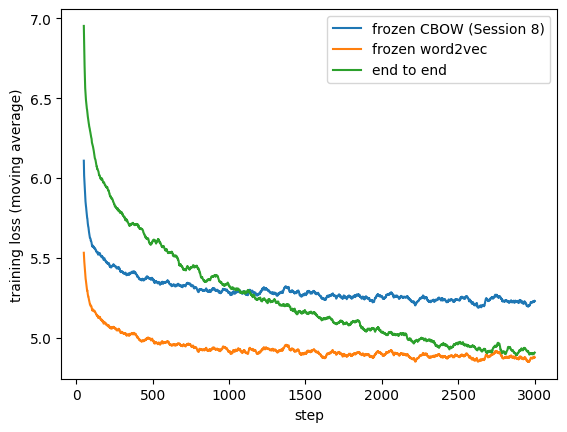

In [20]:
print(f"{'model':26s} {'trainable':>10s} {'perplexity':>11s} {'accuracy':>9s}")
for name, r in results.items():
    print(f"{name:26s} {r['trainable']:>10,d} {r['perplexity']:>11.1f} {r['accuracy']:>9.1%}")

for name, curve in losses.items():
    curve = torch.tensor(curve)
    smooth = curve.unfold(0, 50, 1).mean(1)
    plt.plot(range(50, len(curve) + 1), smooth, label=name)
plt.xlabel("step")
plt.ylabel("training loss (moving average)")
plt.legend()
plt.show()

What do you conclude? Is it worth pre-training the embedding?

- The official word2vec and the end-to-end model reach the **same perplexity** (about 135, against about 590 without context), but the frozen model trains **7.7 times fewer parameters**: the 2 million parameters of the embedding and the decoder were learned once, in a few seconds, by word2vec.
- Look at the loss curves: the frozen word2vec model starts far ahead, the end-to-end model needs the whole training to catch up (after 1500 steps it is still clearly behind). Pre-training is a **head start**.
- Our CBOW of Session 8 is clearly worse than the official word2vec (perplexity about 180): same idea, same size, but negative sampling, subsampling and going through all the text make a difference.
- Here, the pre-trained embedding was learned on the **same** text as the RNN, so it cannot bring new information: with more training, the end-to-end model would end up doing better, since it can adapt the embedding to the task.
  Pre-training pays off when it is done on (much) more data than the task has: think of a classifier trained on 2000 labelled reviews, with an embedding pre-trained on billions of words. This is the idea behind every modern language model: pre-train on a lot of text, then reuse.

### 4. Is the learned embedding similar to word2vec's?

The end-to-end model was never asked to learn a meaningful embedding: only to predict the next word. Let's look at what it learned.

Get the three embedding matrices, of shape `[vocab_size, 100]`: `E_cbow`, `E_w2v` and `E_e2e`.
Then write a function `nearest(E, word, k=8)` returning the `k` words whose embeddings have the highest cosine similarity with the embedding of `word` (excluding `word` itself), and print them side by side for the three embeddings, for a few words.

In [21]:
E_cbow = cbow.encoder.weight.detach().T.cpu()
E_w2v = w2v_in
E_e2e = e2e_lm.embedding.weight.detach().cpu()
embeddings = {"CBOW": E_cbow, "word2vec": E_w2v, "end to end": E_e2e}

def nearest(E, word, k=8):
    sims = F.cosine_similarity(E[stoi[word]][None, :], E, dim=1)
    return [itos[j] for j in sims.argsort(descending=True)[1:k + 1]]

for word in ["france", "three", "however", "zinc", "he", "cat", "walked", "cold"]:
    print(f"[{word}]")
    for name, E in embeddings.items():
        print(f"   {name:10s}: {', '.join(nearest(E, word))}")

[france]
   CBOW      : italy, belgium, austria, denmark, portugal, germany, russia, switzerland
   word2vec  : spain, italy, portugal, belgium, poland, sicily, denmark, norway
   end to end: spain, italy, austria, bavaria, germany, scotland, britain, turkey
[three]
   CBOW      : five, four, six, seven, gwh, eight, fy, knots
   word2vec  : four, five, six, two, seven, eight, one, zero
   end to end: four, five, six, seven, eight, two, fifty, sixty
[however]
   CBOW      : although, though, but, historically, while, essentially, why, trivia
   word2vec  : although, though, but, indeed, moreover, furthermore, unfortunately, nevertheless
   end to end: unfortunately, consequently, nevertheless, indeed, therefore, thus, certainly, though
[zinc]
   CBOW      : detection, oceans, shapes, kidney, pure, aluminium, flowers, broad
   word2vec  : magnesium, sulfur, nickel, chloride, manganese, potassium, sodium, oxide
   end to end: coal, magnesium, chlorine, gas, copper, boron, manganese, alumi

   CBOW      : she, it, teenage, chopin, sharon, mccarthy, eventually, reportedly
   word2vec  : she, it, nobody, oswald, bogart, briefly, hannibal, gehrig
   end to end: she, who, borges, biafra, livingstone, luthor, kissinger, oswald
[cat]
   CBOW      : goat, protagonist, elder, assassin, ss, creature, adjective, grip
   word2vec  : dog, bee, hamster, goat, rat, pepper, girl, cow
   end to end: hamster, insect, weapon, devil, dog, kid, mouse, bone
[walked]
   CBOW      : surrendered, harvest, finish, listen, desires, travelled, looked, turns
   word2vec  : stepped, threw, hung, pulled, walks, turns, sat, turned
   end to end: fell, pulled, flew, marched, dropped, moved, extends, thrown
[cold]
   CBOW      : vietnam, trojan, continuation, gulf, civil, bolshevik, franco, ended
   word2vec  : wet, winter, hot, flame, warm, humid, cool, winters
   end to end: trojan, flame, korean, civil, nuclear, drinking, arabian, wild


To quantify it, write `neighbour_overlap(E1, E2, k=10, n_words=2000)`: for each of the `n_words` most frequent words, take its `k` nearest neighbours in `E1` and in `E2`, and compute the fraction of neighbours they have in common; return the average over the words.

Compute it between the end-to-end embedding and word2vec, between CBOW and word2vec, and, as references:
- between word2vec and a random embedding `torch.randn(vocab_size, 100)` (what you get by chance);
- between word2vec and **another word2vec**, trained exactly the same way but with `seed=1` (how stable is the embedding itself?).

In [22]:
def neighbour_lists(E, k, n_words):
    E = F.normalize(E, dim=1)
    sims = E[:n_words] @ E.T
    sims[torch.arange(n_words), torch.arange(n_words)] = -2  # exclude the word itself
    return sims.topk(k, dim=1).indices

def neighbour_overlap(E1, E2, k=10, n_words=2000):
    n1, n2 = neighbour_lists(E1, k, n_words), neighbour_lists(E2, k, n_words)
    common = (n1[:, :, None] == n2[:, None, :]).any(-1).float().sum(1)
    return (common / k).mean().item()

w2v_seed1 = Word2Vec(sentences, vector_size=100, window=2, sg=0, negative=5, min_count=1, epochs=5, workers=4, seed=1)
E_w2v_seed1, _ = word2vec_matrices(w2v_seed1)

overlaps = {
    "word2vec vs random": neighbour_overlap(E_w2v, torch.randn(vocab_size, 100)),
    "CBOW vs word2vec": neighbour_overlap(E_cbow, E_w2v),
    "end to end vs word2vec": neighbour_overlap(E_e2e, E_w2v),
    "end to end vs CBOW": neighbour_overlap(E_e2e, E_cbow),
    "word2vec vs word2vec (seed 1)": neighbour_overlap(E_w2v, E_w2v_seed1),
}
for name, value in overlaps.items():
    print(f"{name:30s} {value:.1%} of the 10 nearest neighbours in common")

word2vec vs random             0.1% of the 10 nearest neighbours in common
CBOW vs word2vec               18.1% of the 10 nearest neighbours in common
end to end vs word2vec         24.5% of the 10 nearest neighbours in common
end to end vs CBOW             13.2% of the 10 nearest neighbours in common
word2vec vs word2vec (seed 1)  76.8% of the 10 nearest neighbours in common


Finally, the famous property of word2vec: **analogies**. *paris* is to *france* what *rome* is to *italy*, so we hope that $v_{\text{france}} - v_{\text{paris}} + v_{\text{rome}}$ is close to $v_{\text{italy}}$.

The cell below loads the analogy test set of the word2vec paper (questions `a b c d` meaning "a is to b what c is to d"), keeping the questions whose 4 words are in our vocabulary.
Write `analogy_accuracy(E, questions)`: for each question, predict the word whose embedding has the highest cosine similarity with $v_b - v_a + v_c$ (excluding $a$, $b$ and $c$), and return the fraction of correct predictions. Compute it for the three embeddings.

In [23]:
from gensim.test.utils import datapath

questions = []
for line in open(datapath("questions-words.txt")):
    q = line.lower().split()
    if not line.startswith(":") and all(word in stoi for word in q):
        questions.append([stoi[word] for word in q])
questions = torch.tensor(questions)
print(len(questions), "questions, e.g.", [itos[i] for i in questions[0]], [itos[i] for i in questions[-1]])

5451 questions, e.g. ['athens', 'greece', 'baghdad', 'iraq'] ['write', 'writes', 'work', 'works']


In [24]:
def analogy_accuracy(E, questions, batch_size=1000):
    E = F.normalize(E, dim=1)
    correct = 0
    for k in range(0, len(questions), batch_size):
        a, b, c, d = questions[k:k + batch_size].T
        sims = F.normalize(E[b] - E[a] + E[c], dim=1) @ E.T
        rows = torch.arange(len(a))
        sims[rows, a] = sims[rows, b] = sims[rows, c] = -2  # exclude the question words
        correct += (sims.argmax(1) == d).sum().item()
    return correct / len(questions)

for name, E in embeddings.items():
    print(f"{name:10s}: {analogy_accuracy(E, questions):.1%} of analogies solved")

CBOW      : 2.9% of analogies solved


word2vec  : 41.4% of analogies solved


end to end: 5.6% of analogies solved


What do you conclude: is the embedding learned end to end similar to word2vec's?
Look again at the neighbours of *cold* in the end-to-end embedding (and in CBOW): why are *trojan*, *korean*, *civil* or *nuclear* there?

- **Similar neighbourhoods.** The end-to-end embedding groups words the same way word2vec does: countries with countries, numbers with numbers, connectives with connectives, chemical elements together. A quarter of its 10 nearest neighbours are the same as word2vec's (0.1% by chance), **more** than our CBOW, a model built *on purpose* to learn embeddings (18%). Even two word2vec runs that differ only by their random seed only share about 77%: an embedding is not unique, so we cannot expect 100%.
- **Different geometry.** Analogies are a specialty of word2vec (about 40% solved): neither the end-to-end embedding (about 6%) nor our CBOW (about 3%) get them. Note that CBOW is as linear as word2vec: linearity alone is not enough, the regular "directions" (capital of, plural, past tense, ...) come from word2vec's training (negative sampling, subsampling, many passes over the whole text).
- **The task shapes the embedding.** The end-to-end model predicts the *next* word, so it groups words by what follows them: *cold* (war), *trojan* (war), *korean* (war), *civil* (war), *nuclear* (war). Our CBOW does the same, since *war* is in the context window of *cold*. word2vec puts *cold* next to *winter*, *wet* or *hot*.

So yes: an embedding is a **by-product** of training any network on words, and it learns similar neighbourhoods to word2vec; word2vec is the cheap way to get a clean, general-purpose one, with a regular geometry.

### 5. Bonus: generate text

A language model gives a probability for the next word: we can **sample** from it, append the sampled word to the input, and repeat.
Write `generate(model, prompt, n_words=20, temperature=0.8)`, where the scores are divided by `temperature` before the softmax. Try different temperatures: what happens when it is close to 0? Large?

In [ ]:
@torch.no_grad()
def generate(model, prompt, n_words=20, temperature=0.8):
    x = torch.tensor([[stoi.get(word, UNK) for word in prompt.split()]], device=device)
    for _ in range(n_words):
        logits = model(x)[0, -1] / temperature  # scores for the word after the last one
        next_word = torch.multinomial(F.softmax(logits, dim=-1), 1)
        x = torch.cat([x, next_word[None]], dim=1)
    return " ".join(itos[i] for i in x[0])

torch.manual_seed(0)
for temperature in [0.1, 0.8, 1.5]:
    print(f"T={temperature}: {generate(e2e_lm, 'the history of france', temperature=temperature)}")

T=0.1: the history of france and the UNK of the UNK and the UNK of the UNK UNK UNK UNK UNK UNK UNK UNK UNK


T=0.8: the history of france and the al UNK UNK UNK was UNK at UNK and the UNK and the south and east germany was
T=1.5: the history of france at shall end airlines he eventual hit farm eight factions lived history wellington was serving officer capture mormon western breaks


With a temperature close to 0, the model always picks the most likely word: the text quickly gets stuck in a loop of the most frequent tokens (*the UNK of the UNK ...*). With a large temperature, the distribution becomes flatter and the text becomes random.
(The model only sees 32 words of context during training, and is very small: don't expect too much.)